# Chapter 20: ODE, SDE, and Continuous Limits of Algorithms
## Interactive Python & PyTorch Companion Notebook

Welcome to the companion coding notebook for **Chapter 20: ODE, SDE, and Continuous Limits of Algorithms**. In this notebook, we verify all six exercise modules from `exercises/math.md` through analytical checks and numerical simulations:

1. **Exercise 1 (Discrete to Continuous Limits):** Comparing discrete Gradient Descent updates $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta \nabla f(\mathbf{x}_k)$ against the continuous Gradient Flow ODE $\dot{\mathbf{x}}(t) = -\nabla f(\mathbf{x}(t))$, and verifying the Langevin Euler–Maruyama diffusion limit.
2. **Exercises 2 & 3 (Probability Flow ODE & Continuity Equation):** Verifying that the Probability Flow ODE $\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x}, t) - \frac{1}{2}\mathbf{a}(t)\nabla_{\mathbf{x}}\log p_t(\mathbf{x})$ and the 1D Continuity Equation $\partial_t p_t + \partial_x(p_t v_t) = 0$ conserve total probability mass $\int p_t(x)\,dx = 1$ and match the exact marginal densities of the stochastic SDE.
3. **Exercise 4 (Conditional Flow Matching):** Training a PyTorch velocity network $v_\theta(x, t)$ using the Optimal Transport Conditional Flow Matching (CFM) objective $\mathcal{L}_{\mathrm{CFM}}(\theta) = \mathbb{E}\|v_\theta(x_t, t) - (x_1 - x_0)\|_2^2$ and generating samples with a deterministic Euler ODE solver.
4. **Exercises 5 & 6 (State-Space Models as Flows & ODE vs SDE Tradeoffs):** Analyzing Hurwitz eigenvalue stability $\operatorname{Re}(\lambda_i(A)) < 0$, comparing Forward Euler ($\bar{A} = I + \Delta t A$) against Zero-Order Hold ($\bar{A} = \exp(\Delta t A)$) discretization, and contrasting smooth non-crossing ODE streamlines with stochastic SDE sample paths.

In [1]:
import numpy as np
import scipy.linalg as la
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")

Environment initialized successfully.


---
## 1. Exercise 1: Discrete to Continuous Limits (Gradient Flow & Langevin SDE)

### 1.1 Gradient Descent to Gradient Flow ODE
Starting from $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta \nabla f(\mathbf{x}_k)$, identify continuous time $t = k\eta$ and write $\mathbf{x}(t) \approx \mathbf{x}_k$:
$$\frac{\mathbf{x}(t + \eta) - \mathbf{x}(t)}{\eta} = -\nabla f(\mathbf{x}(t)) \xrightarrow{\eta \to 0} \frac{d\mathbf{x}(t)}{dt} = -\nabla f(\mathbf{x}(t)).$$
For an anisotropic quadratic objective $f(x_1, x_2) = \frac{1}{2}(\lambda_1 x_1^2 + \lambda_2 x_2^2)$, the exact continuous trajectory is $\mathbf{x}(t) = (x_1(0)e^{-\lambda_1 t},\, x_2(0)e^{-\lambda_2 t})$.

### 1.2 Discrete Langevin Update as Euler–Maruyama
The discrete update $\mathbf{x}_{k+1} = \mathbf{x}_k + \eta\,\mathbf{s}(\mathbf{x}_k) + \sqrt{2\eta}\,\boldsymbol\epsilon_k$ ($\boldsymbol\epsilon_k \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$) is the Euler–Maruyama discretization of $d\mathbf{X}_t = \mathbf{s}(\mathbf{X}_t)\,dt + \sqrt{2}\,d\mathbf{W}_t$ because the Brownian increment $\Delta\mathbf{W}_k = \mathbf{W}_{(k+1)\eta} - \mathbf{W}_{k\eta}$ has covariance $\eta\mathbf{I}$, so $\sqrt{2}\,\Delta\mathbf{W}_k \stackrel{d}{=} \sqrt{2\eta}\,\boldsymbol\epsilon_k$.

Step size eta = 0.160 | Max trajectory error ||x_k - x(k*eta)||_2 = 1.48958
Step size eta = 0.040 | Max trajectory error ||x_k - x(k*eta)||_2 = 0.17049
Step size eta = 0.010 | Max trajectory error ||x_k - x(k*eta)||_2 = 0.03788


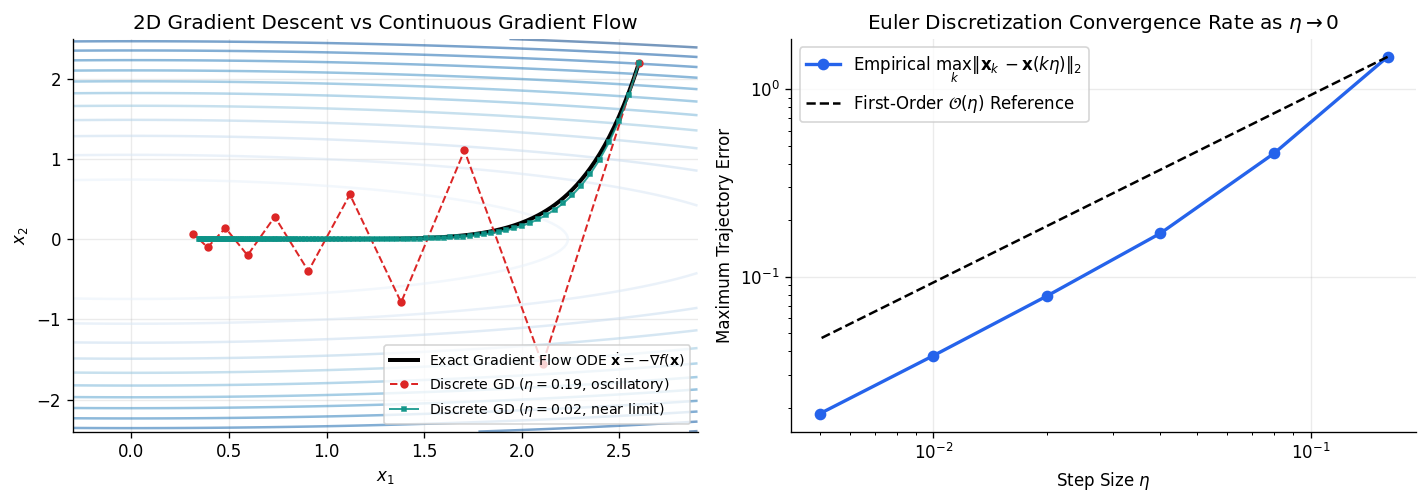

In [2]:
# Anisotropic quadratic bowl: f(x1, x2) = 0.5 * (lam1 * x1^2 + lam2 * x2^2)
lam = np.array([1.0, 9.0])
x0 = np.array([2.6, 2.2])
T_gd = 2.0
t_cont = np.linspace(0.0, T_gd, 400)

# Exact Gradient Flow ODE trajectory
x_ode = x0[None, :] * np.exp(-t_cont[:, None] * lam[None, :])

def run_discrete_gd(eta, T_max):
    n_steps = int(T_max / eta)
    traj = np.zeros((n_steps + 1, 2))
    traj[0] = x0
    for k in range(n_steps):
        traj[k + 1] = traj[k] - eta * (lam * traj[k])
    return traj

traj_large = run_discrete_gd(0.19, T_gd)
traj_med = run_discrete_gd(0.08, T_gd)
traj_small = run_discrete_gd(0.02, T_gd)

# Quantify global sup-norm error vs step size eta
etas_test = np.array([0.16, 0.08, 0.04, 0.02, 0.01, 0.005])
max_errors = []
for eta in etas_test:
    tr = run_discrete_gd(eta, T_gd)
    t_grid = np.arange(len(tr)) * eta
    exact_at_grid = x0[None, :] * np.exp(-t_grid[:, None] * lam[None, :])
    max_errors.append(np.max(np.linalg.norm(tr - exact_at_grid, axis=1)))

for eta, err in zip(etas_test[::2], max_errors[::2]):
    print(f"Step size eta = {eta:.3f} | Max trajectory error ||x_k - x(k*eta)||_2 = {err:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# Contour plot + trajectories
x1_g, x2_g = np.meshgrid(np.linspace(-0.3, 2.9, 150), np.linspace(-2.4, 2.5, 150))
Z = 0.5 * (lam[0] * x1_g ** 2 + lam[1] * x2_g ** 2)
axes[0].contour(x1_g, x2_g, Z, levels=15, cmap="Blues", alpha=0.55)
axes[0].plot(x_ode[:, 0], x_ode[:, 1], "k-", lw=2.4, label=r"Exact Gradient Flow ODE $\dot{\mathbf{x}} = -\nabla f(\mathbf{x})$")
axes[0].plot(traj_large[:, 0], traj_large[:, 1], "o--", color="#dc2626", ms=4, lw=1.2, label=r"Discrete GD ($\eta=0.19$, oscillatory)")
axes[0].plot(traj_small[:, 0], traj_small[:, 1], "s-", color="#0d9488", ms=2.5, lw=1.2, alpha=0.85, label=r"Discrete GD ($\eta=0.02$, near limit)")
axes[0].set_title("2D Gradient Descent vs Continuous Gradient Flow")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="lower right", fontsize=8.5)

axes[1].loglog(etas_test, max_errors, "o-", color="#2563eb", lw=2, label=r"Empirical $\max_k \|\mathbf{x}_k - \mathbf{x}(k\eta)\|_2$")
axes[1].loglog(etas_test, max_errors[0] * (etas_test / etas_test[0]), "k--", lw=1.5, label=r"First-Order $\mathcal{O}(\eta)$ Reference")
axes[1].set_title(r"Euler Discretization Convergence Rate as $\eta \to 0$")
axes[1].set_xlabel(r"Step Size $\eta$")
axes[1].set_ylabel(r"Maximum Trajectory Error")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

---
## 2. Exercises 2, 3 & 6: Continuity Equation, Probability Flow ODE & ODE vs SDE Paths

For the forward Ornstein–Uhlenbeck / VP-SDE:
$$dX_t = -\frac{1}{2}X_t\,dt + dW_t, \qquad X_0 \sim p_0(x),$$
the Fokker–Planck equation $\partial_t p_t = \partial_x(\frac{1}{2}x p_t) + \frac{1}{2}\partial_{xx} p_t$ can be rewritten in **Continuity Equation** form $\partial_t p_t + \partial_x(p_t \tilde{v}_t) = 0$ with the **Probability Flow ODE** velocity field:
$$\tilde{v}_t(x) = -\frac{1}{2}x - \frac{1}{2}\nabla_x \log p_t(x).$$
Notice why the **ODE** and **SDE** share the exact same marginal density $p_t(x)$ at every time $t$, while having radically different trajectories:
- **Probability Flow ODE trajectories** are smooth, deterministic, and non-crossing (ordered quantiles are preserved).
- **SDE trajectories** are rough, stochastic, and frequently cross one another.

Continuity Equation Mass Conservation Check (Integral of p_t(x) dx):
  Masses at t = [0.0, 0.5, 1.2, 2.5]: [np.float64(1.0), np.float64(0.99997), np.float64(0.99994), np.float64(0.99997)]


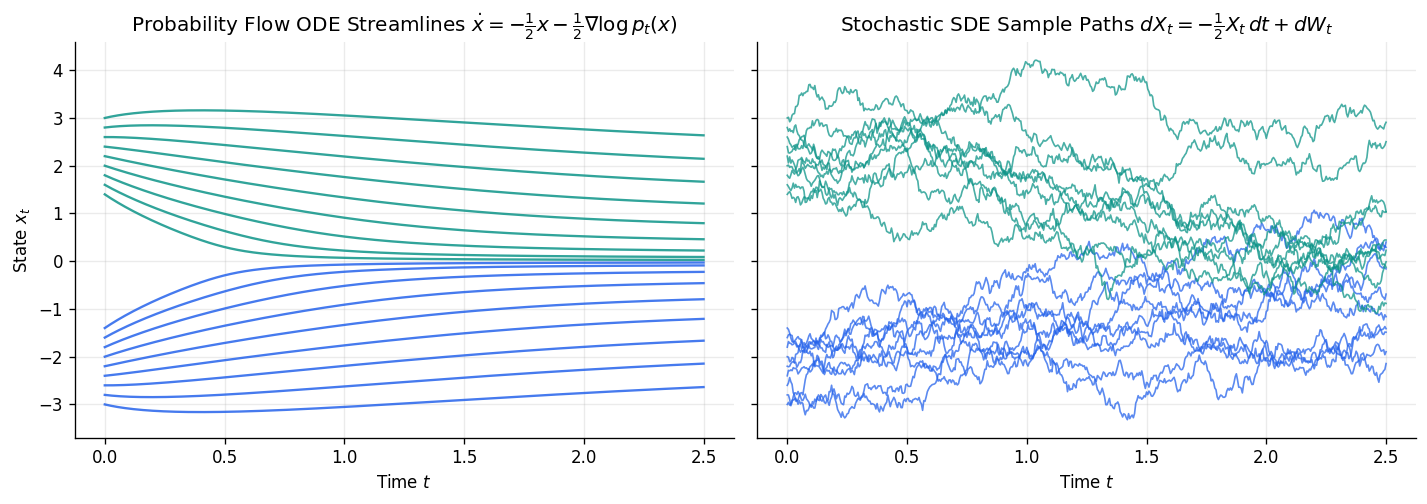

In [3]:
# Compare Forward SDE paths vs Probability Flow ODE paths on a bimodal Gaussian mixture
m1, m2 = -2.2, 2.2
v0 = 0.15
T_pf = 2.5
n_steps_pf = 500
dt_pf = T_pf / n_steps_pf
t_pf = np.linspace(0.0, T_pf, n_steps_pf + 1)

def gmm_density_and_score(x, t):
    alpha = np.exp(-0.5 * t)
    vt = v0 * np.exp(-t) + (1.0 - np.exp(-t))
    mu1, mu2 = m1 * alpha, m2 * alpha
    p1 = 0.5 / np.sqrt(2.0 * np.pi * vt) * np.exp(-0.5 * (x - mu1) ** 2 / vt)
    p2 = 0.5 / np.sqrt(2.0 * np.pi * vt) * np.exp(-0.5 * (x - mu2) ** 2 / vt)
    p = p1 + p2 + 1e-15
    score = (-(x - mu1) / vt * p1 - (x - mu2) / vt * p2) / p
    return p, score

# Initialize 16 deterministic points for path visualization + 6000 particles for marginal check
x_grid_check = np.linspace(-4.5, 4.5, 500)
dx_check = x_grid_check[1] - x_grid_check[0]
masses = [np.sum(gmm_density_and_score(x_grid_check, t_val)[0]) * dx_check for t_val in [0.0, 0.5, 1.2, 2.5]]
print("Continuity Equation Mass Conservation Check (Integral of p_t(x) dx):")
print("  Masses at t = [0.0, 0.5, 1.2, 2.5]:", [round(m, 5) for m in masses])

n_vis = 18
x_init_vis = np.concatenate([np.linspace(-3.0, -1.4, n_vis // 2), np.linspace(1.4, 3.0, n_vis // 2)])
paths_ode = np.zeros((n_vis, n_steps_pf + 1))
paths_sde = np.zeros((n_vis, n_steps_pf + 1))
paths_ode[:, 0] = x_init_vis
paths_sde[:, 0] = x_init_vis

for k in range(n_steps_pf):
    tk = t_pf[k]
    _, sc_ode = gmm_density_and_score(paths_ode[:, k], tk)
    # Probability flow ODE velocity: v_t(x) = -0.5*x - 0.5*score
    v_ode = -0.5 * paths_ode[:, k] - 0.5 * sc_ode
    paths_ode[:, k + 1] = paths_ode[:, k] + v_ode * dt_pf
    # Forward SDE Euler-Maruyama step: dX_t = -0.5*X_t dt + dW_t
    paths_sde[:, k + 1] = paths_sde[:, k] - 0.5 * paths_sde[:, k] * dt_pf + np.sqrt(dt_pf) * np.random.randn(n_vis)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)

for i in range(n_vis):
    color = "#2563eb" if i < n_vis // 2 else "#0d9488"
    axes[0].plot(t_pf, paths_ode[i], color=color, lw=1.4, alpha=0.85)
    axes[1].plot(t_pf, paths_sde[i], color=color, lw=1.0, alpha=0.75)

axes[0].set_title(r"Probability Flow ODE Streamlines $\dot{x} = -\frac{1}{2}x - \frac{1}{2}\nabla\log p_t(x)$")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("State $x_t$")

axes[1].set_title(r"Stochastic SDE Sample Paths $dX_t = -\frac{1}{2}X_t\,dt + dW_t$")
axes[1].set_xlabel("Time $t$")

plt.tight_layout()
plt.show()

---
## 3. Exercise 4: Conditional Flow Matching (CFM) in PyTorch

We train a neural velocity field $\mathbf{v}_\theta(x, t)$ on the **Optimal Transport (straight-line)** Conditional Flow Matching objective:
$$\mathcal{L}_{\mathrm{CFM}}(\theta) = \mathbb{E}_{t \sim \mathcal{U}[0,1],\, x_0 \sim p_0,\, x_1 \sim p_1}\!\left[\left\|v_\theta\big((1-t)x_0 + t x_1,\, t\big) - (x_1 - x_0)\right\|_2^2\right].$$
Once trained, we generate samples from $p_1$ by integrating $\frac{dx}{dt} = v_\theta(x, t)$ from $t=0$ to $t=1$ using just $N=25$ Forward Euler steps.

CFM Training finished: Initial loss = 6.0449 -> Final loss = 3.0065


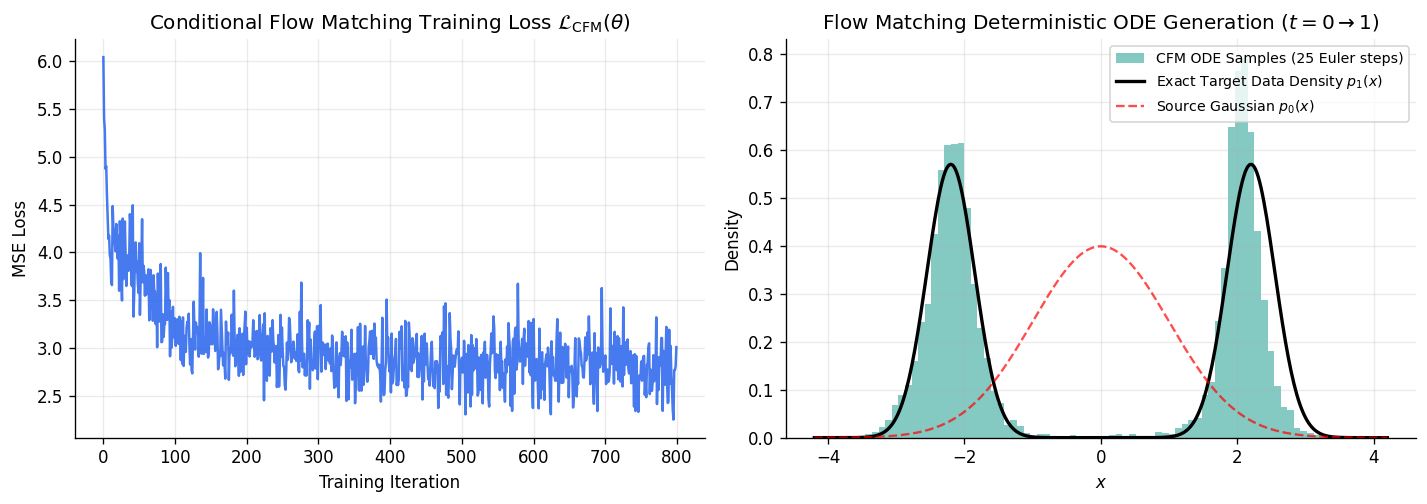

In [4]:
class FlowMatchingNet(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=-1))

def sample_target_bimodal(batch_size):
    '''Target data distribution p_1: bimodal mixture at -2.2 and +2.2.'''
    mask = (torch.rand(batch_size, 1) < 0.5).float()
    means = mask * (-2.2) + (1.0 - mask) * 2.2
    return means + 0.35 * torch.randn(batch_size, 1)

model_cfm = FlowMatchingNet(hidden=64)
optimizer = torch.optim.Adam(model_cfm.parameters(), lr=3e-3)

loss_history = []
batch_size = 512
n_iters = 800

for it in range(n_iters):
    x_1 = sample_target_bimodal(batch_size)
    x_0 = torch.randn_like(x_1)
    t = torch.rand(batch_size, 1)
    
    x_t = (1.0 - t) * x_0 + t * x_1
    u_target = x_1 - x_0
    
    v_pred = model_cfm(x_t, t)
    loss = torch.mean((v_pred - u_target) ** 2)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

print(f"CFM Training finished: Initial loss = {loss_history[0]:.4f} -> Final loss = {loss_history[-1]:.4f}")

# Deterministic Euler ODE sampling from t=0 to t=1 in 25 steps
n_gen_cfm = 6000
n_ode_steps = 25
dt_cfm = 1.0 / n_ode_steps
x_curr = torch.randn(n_gen_cfm, 1)
traj_cfm = [x_curr.numpy().flatten()]

with torch.no_grad():
    for s in range(n_ode_steps):
        t_tensor = torch.full((n_gen_cfm, 1), s * dt_cfm)
        x_curr = x_curr + dt_cfm * model_cfm(x_curr, t_tensor)
        traj_cfm.append(x_curr.numpy().flatten())

samples_cfm = x_curr.numpy().flatten()
true_samples = sample_target_bimodal(n_gen_cfm).numpy().flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

axes[0].plot(loss_history, color="#2563eb", lw=1.5, alpha=0.85)
axes[0].set_title(r"Conditional Flow Matching Training Loss $\mathcal{L}_{\mathrm{CFM}}(\theta)$")
axes[0].set_xlabel("Training Iteration")
axes[0].set_ylabel("MSE Loss")

x_eval = np.linspace(-4.2, 4.2, 400)
p1_exact = (
    0.5 / np.sqrt(2 * np.pi * 0.35 ** 2) * np.exp(-0.5 * (x_eval + 2.2) ** 2 / 0.35 ** 2)
    + 0.5 / np.sqrt(2 * np.pi * 0.35 ** 2) * np.exp(-0.5 * (x_eval - 2.2) ** 2 / 0.35 ** 2)
)
axes[1].hist(samples_cfm, bins=70, density=True, alpha=0.5, color="#0d9488", label="CFM ODE Samples (25 Euler steps)")
axes[1].plot(x_eval, p1_exact, "k-", lw=2.0, label="Exact Target Data Density $p_1(x)$")
axes[1].plot(x_eval, 1.0 / np.sqrt(2 * np.pi) * np.exp(-0.5 * x_eval ** 2), "r--", lw=1.4, alpha=0.7, label="Source Gaussian $p_0(x)$")
axes[1].set_title(r"Flow Matching Deterministic ODE Generation ($t=0 \to 1$)")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## 4. Exercise 5: State-Space Models (SSMs) as Continuous Flows

Consider the linear time-invariant State-Space Model:
$$\dot{\mathbf{x}}(t) = A\mathbf{x}(t) + B\mathbf{u}(t).$$
1. **Hurwitz Stability Condition:** When $\mathbf{u}(t) \equiv \mathbf{0}$, $\mathbf{x}(t) = \exp(At)\mathbf{x}(0) \to \mathbf{0}$ for all $\mathbf{x}(0)$ iff $\operatorname{Re}(\lambda_i(A)) < 0$ for every eigenvalue $\lambda_i$ of $A$.
2. **Euler vs Exact Zero-Order Hold (ZOH) Discretization:**
   - **Forward Euler:** $\bar{A}_{\mathrm{Euler}} = I + \Delta t A$, $\bar{B}_{\mathrm{Euler}} = \Delta t B$.
   - **Exact ZOH:** $\bar{A}_{\mathrm{ZOH}} = \exp(\Delta t A)$, $\bar{B}_{\mathrm{ZOH}} = A^{-1}(\exp(\Delta t A) - I)B$.

Continuous eigenvalues of A: -0.60+3.50j, -0.60-3.50j (Hurwitz: Re < 0)
At dt = 0.08:
  Euler terminal error ||x_N - x(T)||_2 = 0.80487
  ZOH   terminal error ||x_N - x(T)||_2 = 1.32e-15


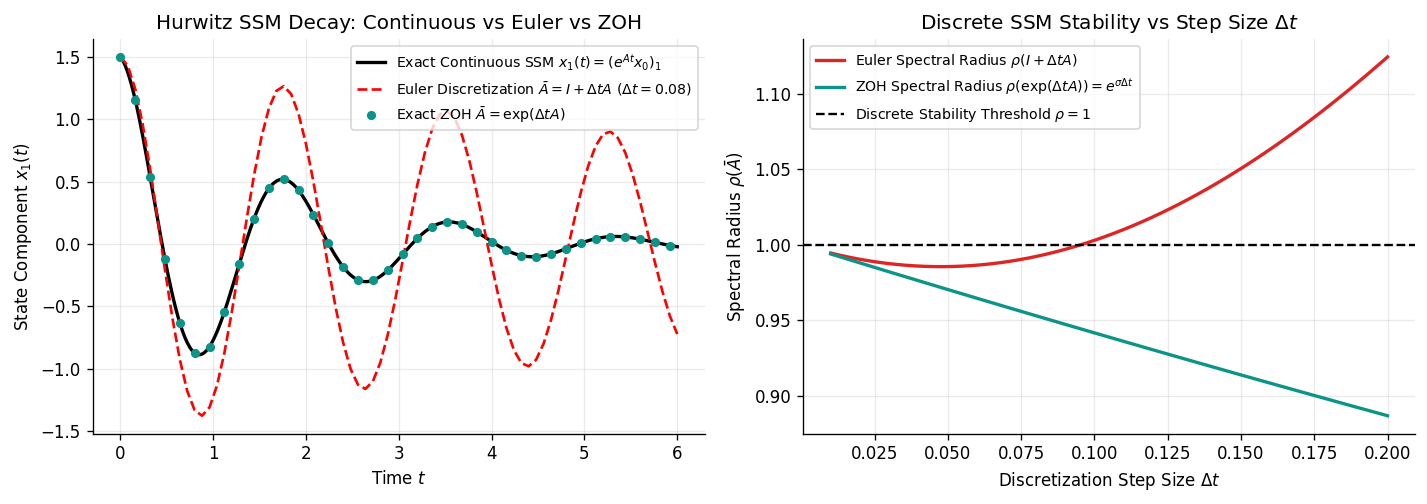

In [5]:
# Damped oscillatory Hurwitz matrix A: eigenvalues = -0.6 +/- 3.5j
sigma_ssm = -0.6
omega_ssm = 3.5
A_ssm = np.array([[sigma_ssm, -omega_ssm],
                  [omega_ssm,  sigma_ssm]])
B_ssm = np.array([[1.0], [0.5]])

eigvals_A = np.linalg.eigvals(A_ssm)
print(f"Continuous eigenvalues of A: {eigvals_A[0]:.2f}, {eigvals_A[1]:.2f} (Hurwitz: Re < 0)")

# Simulate autonomous impulse response from x(0) = [1.5, 0.0]^T
x0_ssm = np.array([1.5, 0.0])
T_ssm = 6.0
t_ssm_fine = np.linspace(0.0, T_ssm, 500)
x_exact_ssm = np.array([la.expm(A_ssm * t) @ x0_ssm for t in t_ssm_fine])

dt_ssm = 0.08
n_steps_ssm = int(T_ssm / dt_ssm)
t_ssm_disc = np.arange(n_steps_ssm + 1) * dt_ssm

A_bar_euler = np.eye(2) + dt_ssm * A_ssm
A_bar_zoh = la.expm(dt_ssm * A_ssm)

x_euler_ssm = np.zeros((n_steps_ssm + 1, 2))
x_zoh_ssm = np.zeros((n_steps_ssm + 1, 2))
x_euler_ssm[0] = x0_ssm
x_zoh_ssm[0] = x0_ssm

for k in range(n_steps_ssm):
    x_euler_ssm[k + 1] = A_bar_euler @ x_euler_ssm[k]
    x_zoh_ssm[k + 1] = A_bar_zoh @ x_zoh_ssm[k]

print(f"At dt = {dt_ssm}:")
print(f"  Euler terminal error ||x_N - x(T)||_2 = {np.linalg.norm(x_euler_ssm[-1] - x_exact_ssm[-1]):.5f}")
print(f"  ZOH   terminal error ||x_N - x(T)||_2 = {np.linalg.norm(x_zoh_ssm[-1] - x_exact_ssm[-1]):.2e}")

# Compare spectral radius across step sizes dt
dt_grid = np.linspace(0.01, 0.20, 60)
rho_euler_list = [np.max(np.abs(np.linalg.eigvals(np.eye(2) + dt_val * A_ssm))) for dt_val in dt_grid]
rho_zoh_list = [np.max(np.abs(np.linalg.eigvals(la.expm(dt_val * A_ssm)))) for dt_val in dt_grid]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

axes[0].plot(t_ssm_fine, x_exact_ssm[:, 0], "k-", lw=2.0, label="Exact Continuous SSM $x_1(t) = (e^{At}x_0)_1$")
axes[0].plot(t_ssm_disc, x_euler_ssm[:, 0], "r--", lw=1.6, label=r"Euler Discretization $\bar{A} = I + \Delta t A$ ($\Delta t=0.08$)")
axes[0].plot(t_ssm_disc[::2], x_zoh_ssm[::2, 0], "o", color="#0d9488", ms=4.5, label=r"Exact ZOH $\bar{A} = \exp(\Delta t A)$")
axes[0].set_title("Hurwitz SSM Decay: Continuous vs Euler vs ZOH")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("State Component $x_1(t)$")
axes[0].legend(loc="upper right", fontsize=8.5)

axes[1].plot(dt_grid, rho_euler_list, color="#dc2626", lw=2.0, label=r"Euler Spectral Radius $\rho(I + \Delta t A)$")
axes[1].plot(dt_grid, rho_zoh_list, color="#0d9488", lw=2.0, label=r"ZOH Spectral Radius $\rho(\exp(\Delta t A)) = e^{\sigma \Delta t}$")
axes[1].axhline(1.0, color="k", ls="--", lw=1.4, label="Discrete Stability Threshold $\\rho = 1$")
axes[1].set_title(r"Discrete SSM Stability vs Step Size $\Delta t$")
axes[1].set_xlabel(r"Discretization Step Size $\Delta t$")
axes[1].set_ylabel(r"Spectral Radius $\rho(\bar{A})$")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()